# Análisis exploratorio del mercado inmobiliario argentino

## 1. Introducción

En este proyecto se analizará un conjunto de datos de publicaciones inmobiliarias de Argentina, con el objetivo de estudiar la distribución de precios, superficies y características de las propiedades.

Se aplicarán técnicas de análisis exploratorio, visualización de variables categóricas y numéricas, cálculo de medidas estadísticas y detección de valores atípicos (outliers).

### Objetivos

- Analizar la distribución de las principales variables del mercado inmobiliario.
- Identificar patrones en los precios y las características de las propiedades.
- Calcular medidas de tendencia central y dispersión.
- Evaluar la asimetría y curtosis de las variables numéricas.
- Detectar y analizar valores atípicos mediante el método IQR.

## 2. Importación de bibliotecas

In [1]:
# Importación de bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 3. Comprobación de la ruta del archivo

In [2]:
# Verificar la ubicación del archivo original

ruta = "../data/venta.csv"

print("¿Existe el archivo?", os.path.exists(ruta))
print("Ruta absoluta:", os.path.abspath(ruta))

¿Existe el archivo? True
Ruta absoluta: d:\CoderHouse\AnalisisdeDatos\analisis-inmobiliario-argentina\data\venta.csv


## 4. Carga del dataset

In [3]:
# Carga del dataset original

df = pd.read_csv(
    ruta,
    sep="|",
    encoding="latin-1",
    low_memory=False
)

print("Dimensiones del dataset:", df.shape)

Dimensiones del dataset: (519792, 35)



## 5. Revisión inicial del dataset

In [4]:
#Primeros registros e informe general
display(df.head())
df.info()

,id,p_usd,p_arg,p_dolar,p_peso,amb,antig,sup_tot,sup_cub,barrio,...,no_aptoc,aptoc,no_aptop,aptop,pisos,ascen,fecha_pub_aviso,exp,direccion,mes
0,42781433,580000.0,NaN,580000.00,NaN,4.0,35.0,500.0,265.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,04nov2017,NaN,Habana 3500,2017m11
1,41311197,309000.0,NaN,309000.00,NaN,4.0,35.0,147.0,132.0,villa urquiza,...,NaN,NaN,NaN,NaN,NaN,NaN,02nov2017,400.0,altolaguirre 3445,2017m11
2,41656002,NaN,4195300.0,238369.31,NaN,3.0,0.0,81.0,81.0,nuñez,...,NaN,NaN,NaN,NaN,9.0,2.0,01nov2017,NaN,Cramer 3000,2017m11
3,42642945,147695.0,NaN,147695.00,NaN,2.0,NaN,52.0,46.0,saavedra,...,NaN,NaN,NaN,NaN,NaN,NaN,01nov2017,NaN,Balbin Ricardo Dr. Av. 4100,2017m11
4,42080435,87000.0,NaN,87000.00,NaN,1.0,NaN,36.0,31.0,caballito,...,NaN,1.0,NaN,NaN,9.0,NaN,03nov2017,1100.0,Donato Alvarez 700,2017m11


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 519792 entries, 0 to 519791
Data columns (total 35 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               519792 non-null  int64  
 1   p_usd            495907 non-null  float64
 2   p_arg            11531 non-null   float64
 3   p_dolar          507438 non-null  float64
 4   p_peso           334040 non-null  float64
 5   amb              513733 non-null  float64
 6   antig            389506 non-null  float64
 7   sup_tot          512462 non-null  float64
 8   sup_cub          493317 non-null  float64
 9   barrio           519718 non-null  object 
 10  lat              519792 non-null  float64
 11  lng              519792 non-null  float64
 12  gimnasio         372365 non-null  float64
 13  balc             467101 non-null  float64
 14  lavadero         450928 non-null  float64
 15  sum_             423902 non-null  float64
 16  parrilla         395522 non-null  floa

## 6. Selección de variables

In [5]:
# Variables seleccionadas para el análisis inmobiliario

columnas_analisis = [
    "id",
    "p_dolar",
    "p_peso",
    "amb",
    "antig",
    "sup_tot",
    "sup_cub",
    "barrio",
    "lat",
    "lng",
    "mes",
    "fecha_pub_aviso",
    "direccion",
    "gimnasio",
    "balc",
    "lavadero",
    "sum_",
    "parrilla",
    "aire",
    "amoblado",
    "solarium",
    "vigilancia",
    "pileta",
    "frente",
    "contrafrente",
    "exp"
]

# Crear una copia con las variables seleccionadas
df_analisis = df[columnas_analisis].copy()

print("Registros:", df_analisis.shape[0])
print("Dimensiones del análisis:", df_analisis.shape)

Registros: 519792
Dimensiones del análisis: (519792, 26)


## 7. Revisión de valores faltantes

In [6]:
# Cantidad y porcentaje de valores faltantes por columna

faltantes = pd.DataFrame({
    "Valores faltantes": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().mean() * 100).round(2)
})

# Ordenar de mayor a menor porcentaje
faltantes = faltantes.sort_values(
    by="Porcentaje (%)",
    ascending=False
)

display(faltantes)

,Valores faltantes,Porcentaje (%)
no_aptop,519477,99.94
no_aptoc,515308,99.14
p_arg,508261,97.78
aptop,471088,90.63
aptoc,466576,89.76
ascen,466406,89.73
pisos,449927,86.56
cochera,443121,85.25
exp,231491,44.54
p_peso,185752,35.74


In [7]:

# Cantidad y porcentaje de valores faltantes en las variables seleccionadas

faltantes_analisis = pd.DataFrame({
    "Valores faltantes": df_analisis.isnull().sum(),
    "Porcentaje (%)": (
        df_analisis.isnull().mean() * 100
    ).round(2)
})

# Ordenar de mayor a menor porcentaje
faltantes_analisis = faltantes_analisis.sort_values(
    by="Porcentaje (%)",
    ascending=False
)

display(faltantes_analisis)


,Valores faltantes,Porcentaje (%)
exp,231491,44.54
p_peso,185752,35.74
amoblado,176844,34.02
gimnasio,147427,28.36
vigilancia,143008,27.51
solarium,135136,26.00
contrafrente,133761,25.73
antig,130286,25.07
pileta,129191,24.85
parrilla,124270,23.91


In [8]:

# Resumen de valores faltantes del conjunto seleccionado

print("Total de registros:", len(df_analisis))
print("Total de celdas:", df_analisis.size)
print("Celdas con valores faltantes:", df_analisis.isnull().sum().sum())
print(
    "Porcentaje total de valores faltantes:",
    round(df_analisis.isnull().mean().mean() * 100, 2),
    "%"
)


Total de registros: 519792
Total de celdas: 13514592
Celdas con valores faltantes: 2011936
Porcentaje total de valores faltantes: 14.89 %


## 8. Análisis exploratorio de datos (EDA)

En esta sección se explorarán las principales variables del dataset para identificar patrones, distribuciones, relaciones e inconsistencias antes de realizar la limpieza de datos.

### 8.1. Análisis de precios y monedas

In [9]:

# Estadísticas descriptivas de las columnas de precios

display(
    df[["p_usd", "p_dolar", "p_peso", "p_arg"]]
    .describe()
    .round(2)
)


,p_usd,p_dolar,p_peso,p_arg
count,4.959070e+05,5.074380e+05,3.340400e+05,1.153100e+04
mean,1.912218e+06,1.870911e+06,8.135192e+07,3.080836e+06
std,4.180856e+08,4.133081e+08,1.663795e+10,1.502571e+07
min,1.000000e+03,1.555200e+02,1.000000e+04,1.000000e+04
25%,1.200000e+05,1.190000e+05,5.410953e+06,1.650000e+05
50%,1.750000e+05,1.700000e+05,8.092275e+06,2.282400e+06
75%,2.900000e+05,2.850000e+05,1.333920e+07,4.180000e+06
max,1.111111e+11,1.111111e+11,4.383333e+12,1.111111e+09


In [10]:

# Comparar los precios en los mismos registros

display(
    df[["p_usd", "p_dolar", "p_peso", "p_arg"]]
    .dropna(how="all")
    .head(15)
)

,p_usd,p_dolar,p_peso,p_arg
0,580000.0,580000.00,NaN,NaN
1,309000.0,309000.00,NaN,NaN
2,NaN,238369.31,NaN,4195300.0
3,147695.0,147695.00,NaN,NaN
4,87000.0,87000.00,NaN,NaN
5,460000.0,460000.00,NaN,NaN
6,80000.0,80000.00,NaN,NaN
7,300000.0,300000.00,NaN,NaN
8,132000.0,132000.00,NaN,NaN
9,NaN,158058.47,NaN,2781829.0


In [11]:

# Analizar la relación entre precios según el mes

precios_peso = df[["mes", "p_dolar", "p_peso"]].dropna().copy()

# Evitar divisiones por cero
precios_peso = precios_peso[
    precios_peso["p_dolar"] > 0
].copy()

# Calcular la relación entre precios
precios_peso["relacion"] = (
    precios_peso["p_peso"] / precios_peso["p_dolar"]
)

# Agrupar por mes y calcular la mediana
relacion_mensual = (
    precios_peso.groupby("mes")
    .agg(
        registros=("relacion", "count"),
        relacion_mediana=("relacion", "median")
    )
)

display(relacion_mensual.head(15))


,registros,relacion_mediana
mes,,
2018m10,19185,37.87
2018m11,20121,38.50
2018m12,17970,38.60
2018m9,5847,39.45
2019m1,24561,38.50
2019m10,12141,61.50
2019m11,13235,63.00
2019m12,12486,63.00
2019m2,20099,39.70


In [12]:

# Ordenar los meses cronológicamente

relacion_mensual = relacion_mensual.copy()

relacion_mensual["_orden"] = pd.PeriodIndex(
    relacion_mensual.index.str.replace("m", "-", regex=False),
    freq="M"
)

relacion_mensual = relacion_mensual.sort_values("_orden")

display(relacion_mensual.drop(columns="_orden"))


,registros,relacion_mediana
mes,,
2018m9,5847,39.45
2018m10,19185,37.87
2018m11,20121,38.50
2018m12,17970,38.60
2019m1,24561,38.50
2019m2,20099,39.70
2019m3,17974,42.00
2019m4,24989,44.00
2019m5,29200,46.00


In [13]:

# Comparar p_usd y p_dolar en los registros donde ambos tienen datos

comparacion = df[["p_usd", "p_dolar"]].dropna()

print("Registros con ambos precios:", len(comparacion))

print(
    "Registros donde los precios coinciden:",
    (comparacion["p_usd"] == comparacion["p_dolar"]).sum()
)

print(
    "Registros donde los precios son diferentes:",
    (comparacion["p_usd"] != comparacion["p_dolar"]).sum()
)


Registros con ambos precios: 495907
Registros donde los precios coinciden: 495907
Registros donde los precios son diferentes: 0


### 8.2. Análisis de superficies

In [14]:

# Estadísticas descriptivas de las superficies

display(
    df_analisis[["sup_tot", "sup_cub"]].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)



,sup_tot,sup_cub
count,512462.00,493317.00
mean,102.28,81.15
std,1381.74,511.19
min,1.00,0.00
25%,44.00,40.00
50%,65.00,58.00
75%,103.00,90.00
90%,170.00,148.00
95%,224.00,198.00
99%,386.00,332.00


In [15]:

# Revisar las 15 superficies totales más grandes

display(
    df_analisis.sort_values(
        "sup_tot", ascending=False
    )[
        ["id", "p_dolar", "amb", "sup_tot",
         "sup_cub", "barrio"]
    ].head(15)
)


,id,p_dolar,amb,sup_tot,sup_cub,barrio
505613,45780358,600000.0,5.0,382637.0,170.00,liniers
127826,43236529,900000.0,5.0,263960.0,263.96,belgrano
139423,43236529,900000.0,5.0,263960.0,263.96,belgrano
115763,43236529,905000.0,5.0,263960.0,263.96,belgrano
81150,43236529,920000.0,5.0,263960.0,263.96,belgrano
151845,43236529,900000.0,5.0,263960.0,263.96,belgrano
132133,43236529,900000.0,5.0,263960.0,263.96,belgrano
101957,43236529,905000.0,5.0,263960.0,263.96,belgrano
396647,44874318,290000.0,3.0,255760.0,199.00,villa del parque
68019,43178986,330000.0,5.0,178800.0,178.80,flores


In [16]:

# Revisar las 15 superficies cubiertas más grandes

display(
    df_analisis.sort_values(
        "sup_cub", ascending=False
    )[
        ["id", "p_dolar", "amb", "sup_tot",
         "sup_cub", "barrio"]
    ].head(15)
)


,id,p_dolar,amb,sup_tot,sup_cub,barrio
363159,44713363,305000.0,3.0,137000.0,130000.0,palermo
350126,44713363,305000.0,3.0,137000.0,130000.0,palermo
422232,44977517,220000.0,5.0,126062.0,126062.0,caballito
396725,44360238,215000.0,5.0,126062.0,126062.0,caballito
409187,44360238,220000.0,5.0,126062.0,126062.0,caballito
514480,45896950,290000.0,3.0,125600.0,114560.0,barrio norte
518868,45885614,240000.0,4.0,104890.0,104890.0,barrio norte
518867,45885613,240000.0,4.0,104890.0,104890.0,barrio norte
474626,45485421,170000.0,2.0,66050.0,46250.0,nuñez
499888,45704670,138000.0,2.0,42000.0,42000.0,belgrano


In [17]:

# Revisar superficies iguales a cero

print(
    "Superficie total igual a cero:",
    (df_analisis["sup_tot"] == 0).sum()
)

print(
    "Superficie cubierta igual a cero:",
    (df_analisis["sup_cub"] == 0).sum()
)


Superficie total igual a cero: 0
Superficie cubierta igual a cero: 105


In [18]:

# Cantidad de superficies superiores a 1.000 m²

print(
    "Superficie total mayor a 1.000 m²:",
    (df_analisis["sup_tot"] > 1000).sum()
)

print(
    "Superficie cubierta mayor a 1.000 m²:",
    (df_analisis["sup_cub"] > 1000).sum()
)


Superficie total mayor a 1.000 m²: 491
Superficie cubierta mayor a 1.000 m²: 160


In [19]:

# Identificar inconsistencias entre superficie cubierta y total

inconsistencias_sup = df_analisis[
    (df_analisis["sup_cub"] > df_analisis["sup_tot"]) &
    df_analisis["sup_cub"].notna() &
    df_analisis["sup_tot"].notna()
].copy()

# Calcular la diferencia entre ambas superficies
inconsistencias_sup["diferencia_sup"] = (
    inconsistencias_sup["sup_cub"] -
    inconsistencias_sup["sup_tot"]
)

print("Registros con superficie cubierta mayor que la total:",
      len(inconsistencias_sup))

display(
    inconsistencias_sup[
        ["id", "p_dolar", "amb", "sup_tot",
         "sup_cub", "diferencia_sup", "barrio"]
    ].head(15)
)


Registros con superficie cubierta mayor que la total: 1569


,id,p_dolar,amb,sup_tot,sup_cub,diferencia_sup,barrio
45,42457408,1.530000e+05,1.0,33.000,60.0,27.000,palermo
321,42518309,2.200000e+05,3.0,64.000,69.0,5.000,palermo hollywood
589,42454717,1.900000e+05,3.0,66.000,69.0,3.000,belgrano
634,42742391,8.500000e+04,2.0,34.000,36.0,2.000,centro
637,41017485,1.500000e+06,5.0,5.008,508.0,502.992,belgrano
890,42811966,8.500000e+04,2.0,42.000,49.0,7.000,congreso
1448,42743283,8.500000e+04,2.0,40.000,46.0,6.000,coghlan
1527,42743910,1.000000e+05,1.0,38.000,41.0,3.000,caballito
1777,42840623,4.829545e+03,3.0,46.000,53.0,7.000,congreso
1835,42796131,1.190000e+05,2.0,56.000,57.0,1.000,caballito


In [20]:

# Clasificar las diferencias entre superficies por rangos

rangos_diferencia = pd.cut(
    inconsistencias_sup["diferencia_sup"],
    bins=[0, 5, 20, 50, 100, float("inf")],
    labels=[
        "1 a 5 m²",
        "Más de 5 a 20 m²",
        "Más de 20 a 50 m²",
        "Más de 50 a 100 m²",
        "Más de 100 m²"
    ]
)

display(
    rangos_diferencia.value_counts().sort_index()
)


diferencia_sup
1 a 5 m²              606
Más de 5 a 20 m²      267
Más de 20 a 50 m²     376
Más de 50 a 100 m²    241
Más de 100 m²          79
Name: count, dtype: int64

### 8.3. Características de las propiedades

In [21]:

# Revisar los valores de las variables de características

variables_caracteristicas = [
    "gimnasio",
    "balc",
    "lavadero",
    "sum_",
    "parrilla",
    "aire",
    "amoblado",
    "solarium",
    "vigilancia",
    "pileta",
    "frente",
    "contrafrente"
]

for columna in variables_caracteristicas:
    print(f"\n{columna}")
    display(df_analisis[columna].value_counts(dropna=False))



gimnasio


gimnasio
0.0    280567
NaN    147427
1.0     91798
Name: count, dtype: int64


balc


balc
1.0    367154
0.0     99947
NaN     52691
Name: count, dtype: int64


lavadero


lavadero
1.0    333221
0.0    117707
NaN     68864
Name: count, dtype: int64

... (14 outputs left out)


frente


frente
1.0    285309
0.0    171695
NaN     62788
Name: count, dtype: int64


contrafrente


contrafrente
0.0    285827
NaN    133761
1.0    100204
Name: count, dtype: int64

### 8.4. Análisis de antigüedad y ambientes

In [22]:

# Revisar posibles valores anómalos

print("Antigüedad negativa:")
print((df_analisis["antig"] < 0).sum())

print("\nAmbientes iguales a cero:")
print((df_analisis["amb"] == 0).sum())

print("\nAmbientes mayores a 10:")
print((df_analisis["amb"] > 10).sum())

print("\nSuperficie total igual a cero:")
print((df_analisis["sup_tot"] == 0).sum())

print("\nSuperficie cubierta igual a cero:")
print((df_analisis["sup_cub"] == 0).sum())


Antigüedad negativa:
38336

Ambientes iguales a cero:
2354

Ambientes mayores a 10:
410

Superficie total igual a cero:
0

Superficie cubierta igual a cero:
105


In [23]:

# Mostrar las 10 propiedades con precios más elevados

display(
    df_analisis.nlargest(10, "p_dolar")[
        ["id", "p_dolar", "amb", "antig",
         "sup_tot", "sup_cub", "barrio"]
    ]
)


,id,p_dolar,amb,antig,sup_tot,sup_cub,barrio
106625,42313493,1.111111e+11,2.0,NaN,64.0,54.0,las cañitas
174825,43791821,1.111111e+11,5.0,NaN,400.0,400.0,palermo
192003,43791821,1.111111e+11,5.0,NaN,400.0,400.0,palermo
201635,43791821,1.111111e+11,5.0,NaN,400.0,400.0,palermo
226363,43791821,1.111111e+11,5.0,NaN,400.0,400.0,palermo
236034,43791821,1.111111e+11,5.0,NaN,400.0,400.0,palermo
274856,43791821,1.111111e+11,5.0,NaN,400.0,400.0,palermo
348961,44711996,1.123123e+10,12.0,NaN,12.0,12.0,abasto
361974,44711996,1.123123e+10,12.0,NaN,12.0,12.0,abasto
307571,44440923,1.234568e+09,2.0,NaN,NaN,NaN,saavedra


In [24]:

# Mostrar las 10 propiedades con mayor superficie total

display(
    df_analisis.nlargest(10, "sup_tot")[
        ["id", "p_dolar", "amb", "antig",
         "sup_tot", "sup_cub", "barrio"]
    ]
)


,id,p_dolar,amb,antig,sup_tot,sup_cub,barrio
505613,45780358,600000.0,5.0,90.0,382637.0,170.00,liniers
81150,43236529,920000.0,5.0,35.0,263960.0,263.96,belgrano
101957,43236529,905000.0,5.0,35.0,263960.0,263.96,belgrano
115763,43236529,905000.0,5.0,35.0,263960.0,263.96,belgrano
127826,43236529,900000.0,5.0,35.0,263960.0,263.96,belgrano
132133,43236529,900000.0,5.0,35.0,263960.0,263.96,belgrano
139423,43236529,900000.0,5.0,35.0,263960.0,263.96,belgrano
151845,43236529,900000.0,5.0,35.0,263960.0,263.96,belgrano
396647,44874318,290000.0,3.0,49.0,255760.0,199.00,villa del parque
68019,43178986,330000.0,5.0,40.0,178800.0,178.80,flores


In [25]:

# Revisar los valores más frecuentes de antigüedad

display(
    df_analisis["antig"]
    .value_counts(dropna=False)
    .sort_index()
    .head(25)
)


antig
-9.0     21616
-2.0        20
-1.0     16700
 0.0     55521
 1.0      7008
 2.0      6944
 3.0      5461
 4.0      5865
 5.0      9774
 6.0      5501
 7.0      4899
 8.0      7278
 9.0      3306
 10.0    12477
 11.0     1543
 12.0     3032
 13.0     1221
 14.0     1357
 15.0     6107
 16.0     1210
 17.0     1275
 18.0     2491
 19.0     1169
 20.0     9503
 21.0      475
Name: count, dtype: int64

In [26]:

# Revisar los valores negativos más frecuentes de antigüedad

display(
    df_analisis.loc[
        df_analisis["antig"] < 0, "antig"
    ].value_counts().head(15)
)


antig
-9.0    21616
-1.0    16700
-2.0       20
Name: count, dtype: int64

In [27]:

# Identificar propiedades con superficies superiores a 10.000 m²

superficies_sospechosas = df_analisis[
    (df_analisis["sup_tot"] > 10000) |
    (df_analisis["sup_cub"] > 10000)
]

print("Registros con superficies superiores a 10.000 m²:",
      len(superficies_sospechosas))

display(
    superficies_sospechosas[
        ["id", "p_dolar", "amb", "antig",
         "sup_tot", "sup_cub", "barrio"]
    ].head(15)
)


Registros con superficies superiores a 10.000 m²: 77


,id,p_dolar,amb,antig,sup_tot,sup_cub,barrio
36756,41140426,689000.0,5.0,7.0,19649.0,199.000,belgrano
42182,43048493,210000.0,4.0,NaN,10733.0,10.733,once
52646,43092658,60000.0,1.0,38.0,26000.0,26.000,congreso
53440,43087074,199900.0,4.0,NaN,10733.0,10.733,once
54791,43083209,208000.0,3.0,36.0,84000.0,75.000,almagro
68019,43178986,330000.0,5.0,40.0,178800.0,178.800,flores
78976,43209062,400000.0,9.0,NaN,49571.0,24.723,san cristobal
81150,43236529,920000.0,5.0,35.0,263960.0,263.960,belgrano
89222,43283185,195000.0,5.0,NaN,11563.0,11.563,congreso
96679,43363071,580000.0,4.0,10.0,115000.0,115.000,palermo hollywood


In [28]:

# Distribución de ambientes superiores a 10

display(
    df_analisis.loc[df_analisis["amb"] > 10, "amb"]
    .value_counts()
    .sort_index()
)

# Revisar los registros con más de 10 ambientes
amb_extremos = df_analisis[df_analisis["amb"] > 10]

display(
    amb_extremos[
        ["id", "amb", "p_dolar", "antig",
         "sup_tot", "sup_cub", "barrio"]
    ].sort_values("amb", ascending=False).head(20)
)


amb
11.0      99
12.0     100
13.0      50
14.0      20
15.0      26
16.0       4
17.0       9
18.0       4
19.0       1
20.0      12
21.0       3
22.0       6
24.0       4
28.0       4
30.0      16
31.0       1
32.0       5
34.0      10
40.0      11
42.0       1
43.0       1
44.0       4
45.0       2
50.0       2
51.0       1
52.0       4
54.0       1
56.0       4
60.0       2
107.0      2
543.0      1
Name: count, dtype: int64

,id,amb,p_dolar,antig,sup_tot,sup_cub,barrio
55667,43145587,543.0,8.000000e+05,4.0,281.0,212.0,villa del parque
135553,43502998,107.0,3.300000e+05,-1.0,107.0,107.0,caballito
145757,43574367,107.0,3.300000e+05,-1.0,107.0,100.0,caballito
273468,44204170,60.0,1.520000e+05,60.0,72.0,70.0,congreso
259041,44204170,60.0,1.520000e+05,60.0,72.0,70.0,congreso
90855,43290168,56.0,1.050000e+05,NaN,58.0,56.0,san telmo
69430,42740100,56.0,1.050000e+06,NaN,248.0,198.0,palermo chico
96993,43290168,56.0,1.050000e+05,NaN,58.0,56.0,san telmo
127985,43290168,56.0,1.050000e+05,NaN,58.0,56.0,san telmo
444288,45171864,54.0,1.250000e+05,36.0,88.0,61.0,caballito


In [29]:

# Revisar registros con antigüedad mayor a 100 años

antig_sospechosa = df_analisis[df_analisis["antig"] > 100]

print("Cantidad de registros:", len(antig_sospechosa))

display(
    antig_sospechosa[
        ["id", "antig", "fecha_pub_aviso", "mes",
         "barrio", "p_dolar", "amb", "sup_tot", "sup_cub"]
    ].sort_values("antig", ascending=False).head(20)
)


Cantidad de registros: 1038


,id,antig,fecha_pub_aviso,mes,barrio,p_dolar,amb,sup_tot,sup_cub
426967,45006589,2019.0,15aug2019,2019m8,villa devoto,168000.0000,2.0,58.0,52.0
426968,45006590,2019.0,15aug2019,2019m8,villa devoto,237000.0000,3.0,82.0,71.0
377607,44822623,2018.0,24jun2019,2019m6,saavedra,133000.0000,2.0,70.0,52.0
364760,44322049,2018.0,13jun2019,2019m6,constitucion,108000.0000,2.0,65.0,55.0
412434,44899535,2018.0,12jul2019,2019m7,villa urquiza,147000.0000,2.0,50.0,45.0
403147,44899536,2018.0,12jul2019,2019m7,villa urquiza,147000.0000,2.0,51.0,45.0
288068,44322049,2018.0,26feb2019,2019m2,constitucion,108000.0000,2.0,65.0,55.0
285183,44298817,2018.0,20feb2019,2019m2,villa urquiza,151500.0000,2.0,50.0,45.0
284472,44298819,2018.0,20feb2019,2019m2,villa urquiza,154500.0000,2.0,51.0,45.0
426286,45017436,2018.0,13aug2019,2019m8,villa urquiza,144000.0000,2.0,51.0,45.0


In [30]:

# Clasificar los valores extremos de antigüedad

print("Entre 101 y 999 años:")
print(((df_analisis["antig"] > 100) & (df_analisis["antig"] < 1000)).sum())

print("\nEntre 1900 y 2019:")
print(((df_analisis["antig"] >= 1900) & (df_analisis["antig"] <= 2019)).sum())

print("\nMayores a 2019:")
print((df_analisis["antig"] > 2019).sum())

# Ver los valores entre 1900 y 2019
display(
    df_analisis.loc[
        df_analisis["antig"].between(1900, 2019),
        ["id", "antig", "fecha_pub_aviso", "mes", "barrio"]
    ].sort_values("antig", ascending=False)
)


Entre 101 y 999 años:
933

Entre 1900 y 2019:
104

Mayores a 2019:
0


,id,antig,fecha_pub_aviso,mes,barrio
426968,45006590,2019.0,15aug2019,2019m8,villa devoto
426967,45006589,2019.0,15aug2019,2019m8,villa devoto
284472,44298819,2018.0,20feb2019,2019m2,villa urquiza
288068,44322049,2018.0,26feb2019,2019m2,constitucion
285177,44298816,2018.0,20feb2019,2019m2,villa urquiza
...,...,...,...,...,...
112616,43413730,1930.0,31may2018,2018m5,congreso
95622,43325616,1930.0,05may2018,2018m5,congreso
126227,43239742,1928.0,15jun2018,2018m6,balvanera
82890,43239894,1928.0,10apr2018,2018m4,congreso


## 9. Limpieza y tratamiento de datos

En esta sección se tratarán los valores inconsistentes identificados durante el análisis exploratorio. Se conservarán los registros originales y se reemplazarán por valores faltantes únicamente aquellos datos que no resulten válidos o confiables.

### 9.1. Tratamiento de valores de antigüedad

In [31]:

# Limpieza de la variable antigüedad

# Crear una copia de trabajo
df_analisis = df_analisis.copy()

# Contabilizar los valores sospechosos antes de modificarlos
negativos = (df_analisis["antig"] < 0).sum()
anios_sospechosos = df_analisis["antig"].between(1900, 2019).sum()
antig_extrema = (df_analisis["antig"] > 100).sum()

# Convertir valores inválidos y extremos en NaN
df_analisis.loc[df_analisis["antig"] < 0, "antig"] = np.nan

df_analisis.loc[
    df_analisis["antig"].between(1900, 2019),
    "antig"
] = np.nan

df_analisis.loc[df_analisis["antig"] > 100, "antig"] = np.nan

# Mostrar resultados
print("Valores negativos tratados:", negativos)
print("Posibles años tratados:", anios_sospechosos)
print("Antigüedades superiores a 100 tratadas:", antig_extrema)
print("Valores negativos restantes:", (df_analisis["antig"] < 0).sum())
print("Valores superiores a 100 restantes:", (df_analisis["antig"] > 100).sum())
print("Total de valores faltantes:", df_analisis["antig"].isna().sum())

display(df_analisis["antig"].describe().round(2))


Valores negativos tratados: 38336
Posibles años tratados: 104
Antigüedades superiores a 100 tratadas: 1038
Valores negativos restantes: 0
Valores superiores a 100 restantes: 0
Total de valores faltantes: 169660


count    350132.00
mean         28.36
std          22.96
min           0.00
25%           5.00
50%          30.00
75%          45.00
max         100.00
Name: antig, dtype: float64

### 9.2. Tratamiento de valores de ambientes

In [32]:

# Distribución de ambientes antes del tratamiento

display(
    df_analisis["amb"]
    .value_counts(dropna=False)
    .sort_index()
)


amb
0.0        2354
1.0       98896
2.0      136914
3.0      143316
4.0       92427
5.0       26645
6.0        7901
7.0        2878
8.0        1357
9.0         347
10.0        288
11.0         99
12.0        100
13.0         50
14.0         20
15.0         26
16.0          4
17.0          9
18.0          4
19.0          1
20.0         12
21.0          3
22.0          6
24.0          4
28.0          4
30.0         16
31.0          1
32.0          5
34.0         10
40.0         11
42.0          1
43.0          1
44.0          4
45.0          2
50.0          2
51.0          1
52.0          4
54.0          1
56.0          4
60.0          2
107.0         2
543.0         1
NaN        6059
Name: count, dtype: int64

In [33]:

# Reemplazar cero ambientes por valores faltantes

amb_cero = (df_analisis["amb"] == 0).sum()

df_analisis.loc[df_analisis["amb"] == 0, "amb"] = np.nan

print("Valores cero tratados:", amb_cero)
print("Valores cero restantes:", (df_analisis["amb"] == 0).sum())
print("Valores faltantes actuales:", df_analisis["amb"].isna().sum())


Valores cero tratados: 2354
Valores cero restantes: 0
Valores faltantes actuales: 8413


In [34]:

# Reemplazar valores superiores a 50 ambientes por valores faltantes

amb_extremos = (df_analisis["amb"] > 50).sum()

df_analisis.loc[df_analisis["amb"] > 50, "amb"] = np.nan

print("Valores extremos tratados:", amb_extremos)
print("Valores superiores a 50 restantes:", (df_analisis["amb"] > 50).sum())
print("Valores faltantes actuales:", df_analisis["amb"].isna().sum())


Valores extremos tratados: 15
Valores superiores a 50 restantes: 0
Valores faltantes actuales: 8428


## 10. Medidas resumen y análisis de distribución

En esta sección se analizará la distribución de las principales variables numéricas mediante el cálculo de medidas estadísticas. Se utilizarán la asimetría y la curtosis para identificar el comportamiento de los datos y detectar posibles distribuciones alejadas de la normalidad.

In [35]:
# Variables numéricas principales

variables_numericas = [
    "p_dolar",
    "amb",
    "antig",
    "sup_tot",
    "sup_cub"
]

# Calcular asimetría y curtosis

analisis_distribucion = pd.DataFrame({
    "Asimetría": df_analisis[variables_numericas].skew(),
    "Curtosis": df_analisis[variables_numericas].kurtosis()
})

# Mostrar resultados

display(analisis_distribucion.round(2))

,Asimetría,Curtosis
p_dolar,268.09,72047.85
amb,2.61,46.41
antig,0.38,-0.62
sup_tot,172.20,34090.94
sup_cub,219.22,51880.47


## 11. Detección y clasificación de outliers

En esta sección se identificarán valores atípicos (outliers) en las principales variables numéricas mediante el método del rango intercuartílico (IQR).

Se calcularán los límites inferior y superior para cada variable y se cuantificará la cantidad y el porcentaje de registros que quedan fuera de esos límites.

Los valores identificados se conservarán para su posterior análisis, sin eliminarlos automáticamente.

In [36]:
# Variables numéricas para detectar outliers

variables_iqr = [
    "p_dolar",
    "amb",
    "sup_tot",
    "sup_cub"
]

# Calcular límites IQR y cantidad de outliers

resultados_iqr = []

for columna in variables_iqr:

    Q1 = df_analisis[columna].quantile(0.25)
    Q3 = df_analisis[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = (
        (df_analisis[columna] < limite_inferior) |
        (df_analisis[columna] > limite_superior)
    )

    cantidad = outliers.sum()
    porcentaje = (cantidad / df_analisis[columna].notna().sum()) * 100

    resultados_iqr.append({
        "Variable": columna,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Cantidad de outliers": cantidad,
        "Porcentaje (%)": porcentaje
    })

# Crear tabla de resultados

tabla_iqr = pd.DataFrame(resultados_iqr)

display(tabla_iqr.round(2))

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Cantidad de outliers,Porcentaje (%)
0,p_dolar,119000.0,285000.0,166000.0,-130000.0,534000.0,48775,9.61
1,amb,2.0,4.0,2.0,-1.0,7.0,2387,0.47
2,sup_tot,44.0,103.0,59.0,-44.5,191.5,38860,7.58
3,sup_cub,40.0,90.0,50.0,-35.0,165.0,37676,7.64


In [37]:
# Crear una copia para clasificar los valores

df_iqr = df_analisis.copy()

# Clasificar cada variable según los límites IQR

for columna in variables_iqr:

    Q1 = df_analisis[columna].quantile(0.25)
    Q3 = df_analisis[columna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    df_iqr[f"{columna}_clasificacion"] = np.where(
        df_analisis[columna].isna(),
        "Sin dato",
        np.where(
            (df_analisis[columna] < limite_inferior) |
            (df_analisis[columna] > limite_superior),
            "Outlier",
            "Habitual"
        )
    )

print("Clasificación de registros completada.")

Clasificación de registros completada.


In [38]:
# Resumen de registros según su clasificación

for columna in variables_iqr:

    print(f"\nVariable: {columna}")

    display(
        df_iqr[f"{columna}_clasificacion"]
        .value_counts(dropna=False)
        .to_frame("Cantidad de registros")
    )


Variable: p_dolar


,Cantidad de registros
p_dolar_clasificacion,
Habitual,458663
Outlier,48775
Sin dato,12354



Variable: amb


,Cantidad de registros
amb_clasificacion,
Habitual,508977
Sin dato,8428
Outlier,2387



Variable: sup_tot


,Cantidad de registros
sup_tot_clasificacion,
Habitual,473602
Outlier,38860
Sin dato,7330



Variable: sup_cub


,Cantidad de registros
sup_cub_clasificacion,
Habitual,455641
Outlier,37676
Sin dato,26475


## 12. Visualizaciones

En esta sección se representarán gráficamente las distribuciones de las principales variables y las características del mercado inmobiliario. Se utilizarán gráficos Boxplot, Barplot y Violin Plot para facilitar la interpretación de los datos y observar posibles valores extremos.

### 12.1. Boxplots de las principales variables numéricas

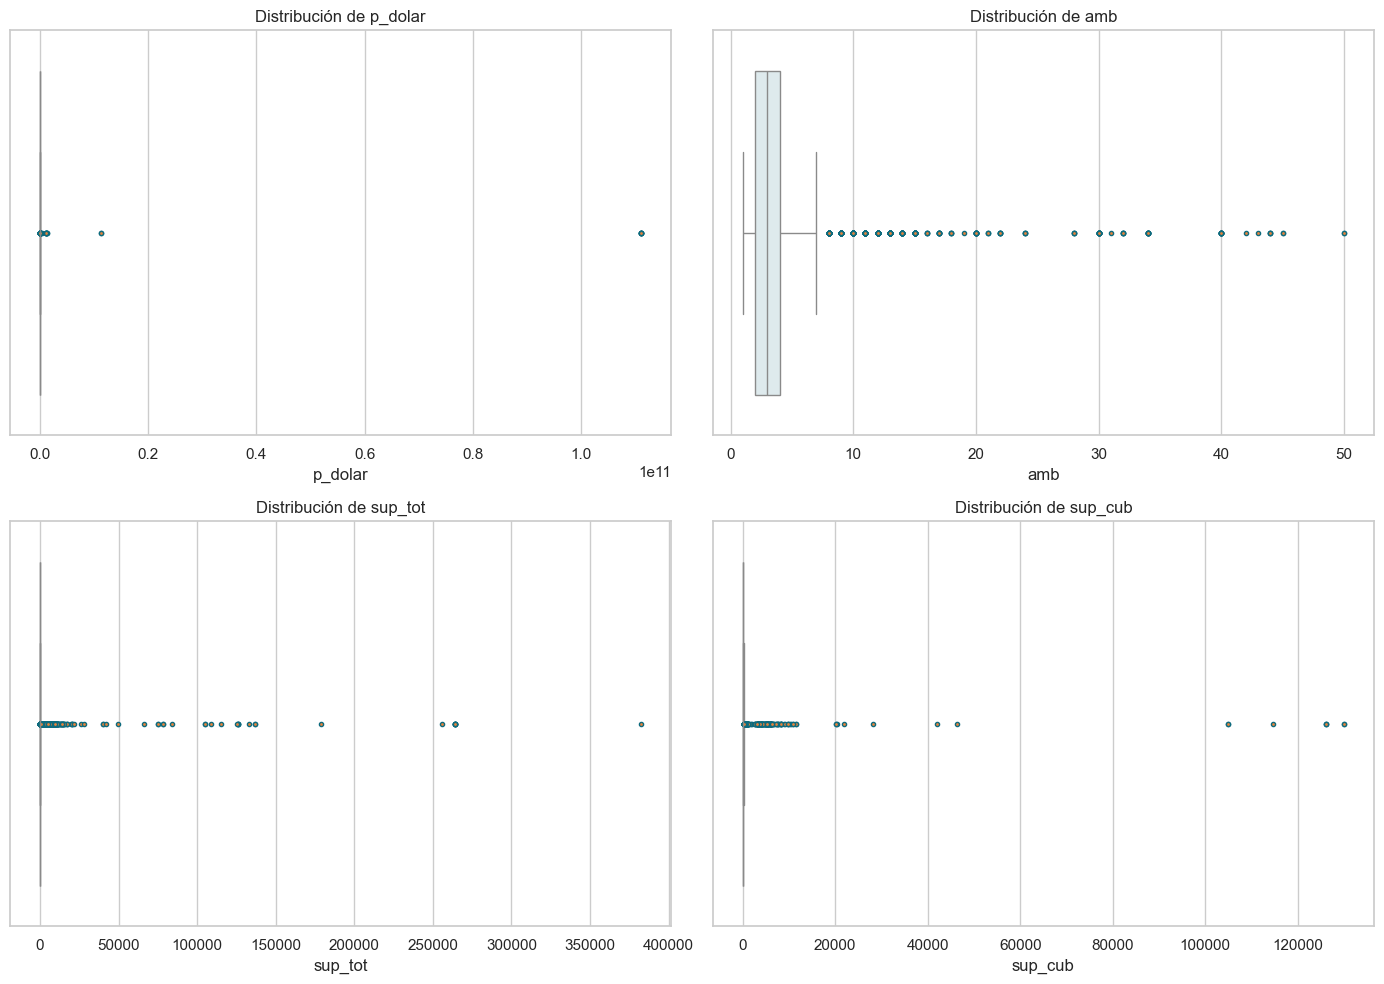

In [39]:
# Boxplots de las principales variables numéricas

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, columna in zip(axes.flat, variables_iqr):

    sns.boxplot(
        x=df_analisis[columna],
        ax=ax,
        color="#DCECEF",
        flierprops={
            "marker": "o",
            "markerfacecolor": "#E8833A",
            "markeredgecolor": "#0E6B7E",
            "markersize": 3
        }
    )

    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel(columna)

plt.tight_layout()
plt.show()

### 12.2. Barplot: barrios con mayor cantidad de publicaciones

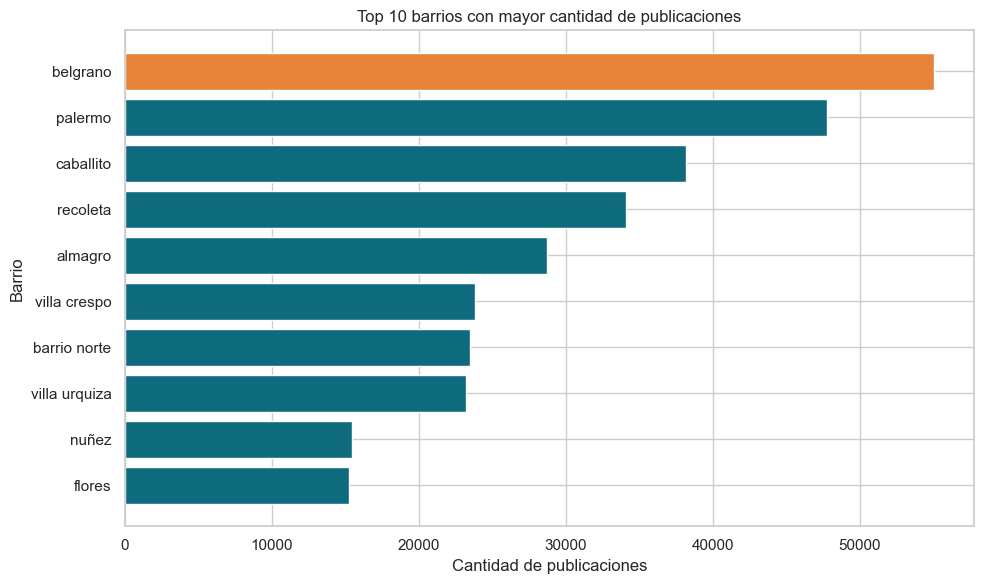

In [40]:
# Cantidad de publicaciones por barrio

top_barrios = (
    df_analisis["barrio"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

# Destacar el barrio con más publicaciones

colores = [
    "#E8833A" if barrio == top_barrios.idxmax() else "#0E6B7E"
    for barrio in top_barrios.index
]

# Crear gráfico

plt.figure(figsize=(10, 6))

plt.barh(
    top_barrios.index,
    top_barrios.values,
    color=colores
)

plt.title("Top 10 barrios con mayor cantidad de publicaciones")
plt.xlabel("Cantidad de publicaciones")
plt.ylabel("Barrio")

plt.tight_layout()
plt.show()

### 12.3. Violin Plot: distribución de precios según cantidad de ambientes

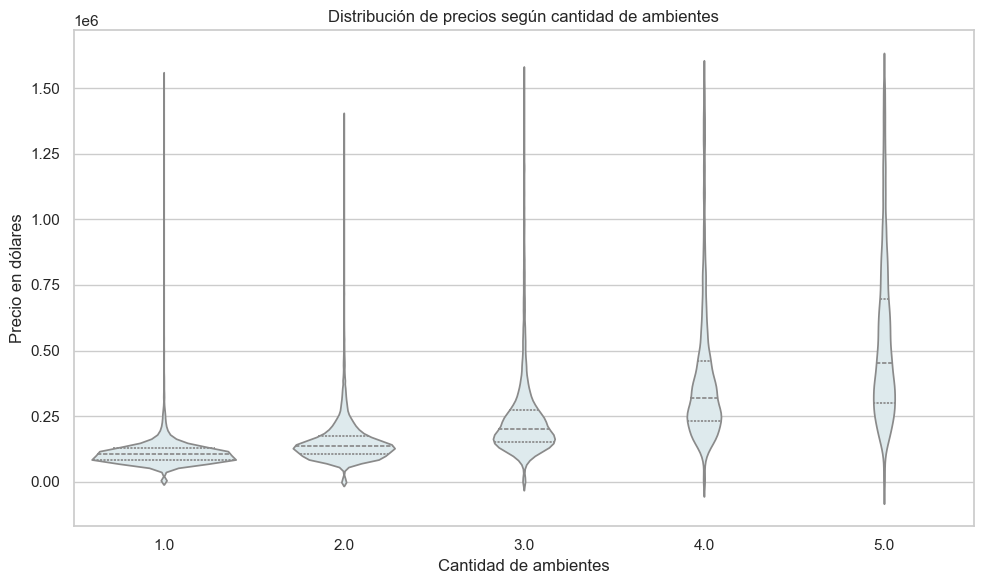

In [41]:
# Preparar datos para el Violin Plot

df_violin = df_analisis[
    (df_analisis["p_dolar"] > 0) &
    (df_analisis["amb"].isin([1, 2, 3, 4, 5]))
].copy()

# Calcular percentil 99 para limitar valores extremos solo en el gráfico

limite_p99 = df_violin["p_dolar"].quantile(0.99)

df_violin = df_violin[
    df_violin["p_dolar"] <= limite_p99
]

# Crear Violin Plot

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df_violin,
    x="amb",
    y="p_dolar",
    color="#DCECEF",
    inner="quartile"
)

plt.title("Distribución de precios según cantidad de ambientes")
plt.xlabel("Cantidad de ambientes")
plt.ylabel("Precio en dólares")

plt.tight_layout()
plt.show()

### 12.4. Conclusión de las visualizaciones

Las visualizaciones permiten observar diferencias importantes en la distribución de los precios y las superficies de las propiedades. Los gráficos Boxplot muestran la presencia de valores extremos en las variables analizadas, mientras que el Barplot permite identificar los barrios con mayor cantidad de publicaciones.

Por su parte, el Violin Plot permite comparar la distribución de los precios según la cantidad de ambientes y observar su dispersión.

En conjunto, los gráficos complementan el análisis estadístico y facilitan la identificación de patrones y posibles inconsistencias en los datos.

## 13. Decisiones sobre inconsistencias en superficies


Durante el análisis exploratorio se identificaron registros con posibles inconsistencias en las variables de superficie, como propiedades cuya superficie cubierta supera la superficie total y publicaciones con superficie cubierta igual a cero.

También se observaron valores extremos, incluyendo superficies muy superiores a las habituales.

Como no es posible determinar con certeza cuáles son los valores correctos, se decidió conservar estos registros sin modificarlos ni eliminarlos automáticamente.

Estas observaciones se tendrán en cuenta al interpretar los resultados del análisis y la detección de valores atípicos mediante el método IQR.